# Global Uemployment and Economic Trend Analysis

### Project Objective

This project aims to analyze and understand the relationship between economic growth and unemployment trends across multiple countries. It focuses on identifying patterns in GDP growth, total unemployment, and youth unemployment over time. The project also compares developed and developing countries to understand differences in economic and employment behavior.

The final goal is to extract meaningful insights that help explain how economic conditions influence labor market trends across different regions.


### Dataset Information
* Source: World Bank Open Data (World Development Indicators)
* Countries: India, United States, China, Germany, Japan, Australia, United Kingdom
* Time Period: 2017 – 2024
* Indicators Used:
     *  GDP Growth (annual %)
     * Unemployment, total (% of total labor force)
     *  Unemployment, youth total (% ages 15–24)

### Libraries Used
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Scikit-learn

In [42]:
# Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

## DATA CLEANING
1. Imported libraries and loaded the dataset.
2. Replaced missing symbols (`..`) with null values.
3. Removed unnecessary columns from the dataset.
4. Renamed columns for better readability.
5. Converted the dataset into tidy/structured format.
6. Checked dataset shape, datatypes, and missing values.
7. Filled missing values using interpolation.
8. Saved the cleaned dataset for further analysis.


In [43]:
df = pd.read_excel("unemployment_WDI_Data_.xlsx")
df.head(5)

,Country Name,Country Code,Series Name,Series Code,2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
0,Australia,AUS,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,2.29331,2.874170,2.194017,-0.133532,2.006948,4.253046,3.583821,1.373408,..
1,Australia,AUS,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.NE.ZS,5.604,5.345000,5.143000,6.394000,5.022000,3.728,3.668,3.942,..
2,Australia,AUS,"Unemployment, youth total (% of total labor fo...",SL.UEM.1524.NE.ZS,12.676,11.938000,11.449000,14.150000,11.156000,8.449,8.319,9.309,..
3,China,CHN,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,6.891266,6.756718,6.068502,2.340188,8.570085,3.134189,5.414843,4.977357,..
4,China,CHN,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.NE.ZS,3.775,4.930000,5.150000,5.610000,5.110000,4.569,..,..,..


In [44]:
df.shape

(21, 13)

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Country Name   21 non-null     object 
 1   Country Code   21 non-null     object 
 2   Series Name    21 non-null     object 
 3   Series Code    21 non-null     object 
 4   2017 [YR2017]  21 non-null     object 
 5   2018 [YR2018]  21 non-null     float64
 6   2019 [YR2019]  21 non-null     float64
 7   2020 [YR2020]  21 non-null     float64
 8   2021 [YR2021]  21 non-null     float64
 9   2022 [YR2022]  21 non-null     object 
 10  2023 [YR2023]  21 non-null     object 
 11  2024 [YR2024]  21 non-null     object 
 12  2025 [YR2025]  21 non-null     object 
dtypes: float64(4), object(9)
memory usage: 2.3+ KB


In [46]:
# replace ".." into null values (Nan)
df.replace("..", np.nan, inplace=True)

C:\Users\micky\AppData\Local\Temp\ipykernel_9448\484027041.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace("..", np.nan, inplace=True)


In [47]:
# remove unnecessary columns
df = df.drop(columns=["Country Code", "Series Code", "2025 [YR2025]"])
df.columns

Index(['Country Name', 'Series Name', '2017 [YR2017]', '2018 [YR2018]',
       '2019 [YR2019]', '2020 [YR2020]', '2021 [YR2021]', '2022 [YR2022]',
       '2023 [YR2023]', '2024 [YR2024]'],
      dtype='object')

In [48]:
# Rename the columns
df.rename(columns={
    "Country Name":"Country",
    "Series Name":"Indicator",
    '2017 [YR2017]':'2017',
    '2018 [YR2018]':'2018',
    '2019 [YR2019]':'2019',
    '2020 [YR2020]':'2020',
    '2021 [YR2021]':'2021',
    '2022 [YR2022]':'2022',
    '2023 [YR2023]':'2023',
    '2024 [YR2024]':'2024',
}, inplace=True)

In [49]:
# change the data format from wide to long
df_melted = df.melt(
    id_vars=["Country", "Indicator"],
    var_name="Year",
    value_name="Value"
)
df_melted.head()

,Country,Indicator,Year,Value
0,Australia,GDP growth (annual %),2017,2.293310
1,Australia,"Unemployment, total (% of total labor force) (...",2017,5.604000
2,Australia,"Unemployment, youth total (% of total labor fo...",2017,12.676000
3,China,GDP growth (annual %),2017,6.891266
4,China,"Unemployment, total (% of total labor force) (...",2017,3.775000


In [50]:
# convert indicatrors into separate Columns
df_final = df_melted.pivot_table(
    index=["Country", "Year"],
    columns="Indicator",
    values="Value"
).reset_index()
df_final.columns.name=None
df = df_final
df.head()

,Country,Year,GDP growth (annual %),"Unemployment, total (% of total labor force) (national estimate)","Unemployment, youth total (% of total labor force ages 15-24) (national estimate)"
0,Australia,2017,2.293310,5.604,12.676
1,Australia,2018,2.874170,5.345,11.938
2,Australia,2019,2.194017,5.143,11.449
3,Australia,2020,-0.133532,6.394,14.150
4,Australia,2021,2.006948,5.022,11.156


In [53]:
# Rename column names
df.rename(
    columns={
      "GDP growth (annual %)":"GDP_Growth",
      "Unemployment, total (% of total labor force) (national estimate)":"Unemployment_Total",
      "Unemployment, youth total (% of total labor force ages 15-24) (national estimate)":"Youth_Unemployment"
    }
     , inplace=True)
df.head()

,Country,Year,GDP_Growth,Unemployment_Total,Youth_Unemployment
0,Australia,2017,2.293310,5.604,12.676
1,Australia,2018,2.874170,5.345,11.938
2,Australia,2019,2.194017,5.143,11.449
3,Australia,2020,-0.133532,6.394,14.150
4,Australia,2021,2.006948,5.022,11.156


In [54]:
# Change the datatype of the column "Year" from object to int
df["Year"] = df["Year"].astype(int)

In [55]:
# handling missing values 
df.interpolate(inplace=True)

C:\Users\micky\AppData\Local\Temp\ipykernel_9448\977857708.py:2: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df.interpolate(inplace=True)


In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56 entries, 0 to 55
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Country             56 non-null     object 
 1   Year                56 non-null     int32  
 2   GDP_Growth          56 non-null     float64
 3   Unemployment_Total  56 non-null     float64
 4   Youth_Unemployment  56 non-null     float64
dtypes: float64(3), int32(1), object(1)
memory usage: 2.1+ KB


In [57]:
df.to_csv("cleaned_dataset.csv", index=False)

# Exploratory Data Analysis (EDA)

In [58]:
df=pd.read_csv("cleaned_dataset.csv")

In [60]:
df.shape

(56, 5)

In [61]:
df.columns

Index(['Country', 'Year', 'GDP_Growth', 'Unemployment_Total',
       'Youth_Unemployment'],
      dtype='object')

In [59]:
df.describe()

,Year,GDP_Growth,Unemployment_Total,Youth_Unemployment
count,56.000000,56.000000,56.000000,56.000000
mean,2020.500000,2.606989,4.322304,10.721589
std,2.312024,3.668317,1.320571,5.091293
min,2017.000000,-10.047897,2.351000,3.666000
25%,2018.750000,1.089251,3.613500,6.879000
50%,2020.500000,2.548100,4.034333,10.288750
75%,2022.250000,5.020443,5.044000,13.126750
max,2024.000000,9.689592,8.055000,26.171000


#### Observations
- The dataset contains 56 observations for each variable, covering seven countries from 2017 to 2024.
- The average GDP growth was 2.61%, with values ranging from −10.05% to 9.69%.
- Total unemployment averaged 4.32%, ranging from 2.35% to 8.06%.
- Youth unemployment averaged 10.72%, which was higher than total unemployment across the dataset.
- GDP growth showed considerable variation, while total unemployment had a smaller spread of values.

## 1. Univariate Analysis

#### 1.1 (GDP Growth, Total Unemployment, Youth Unemployment) Distribution

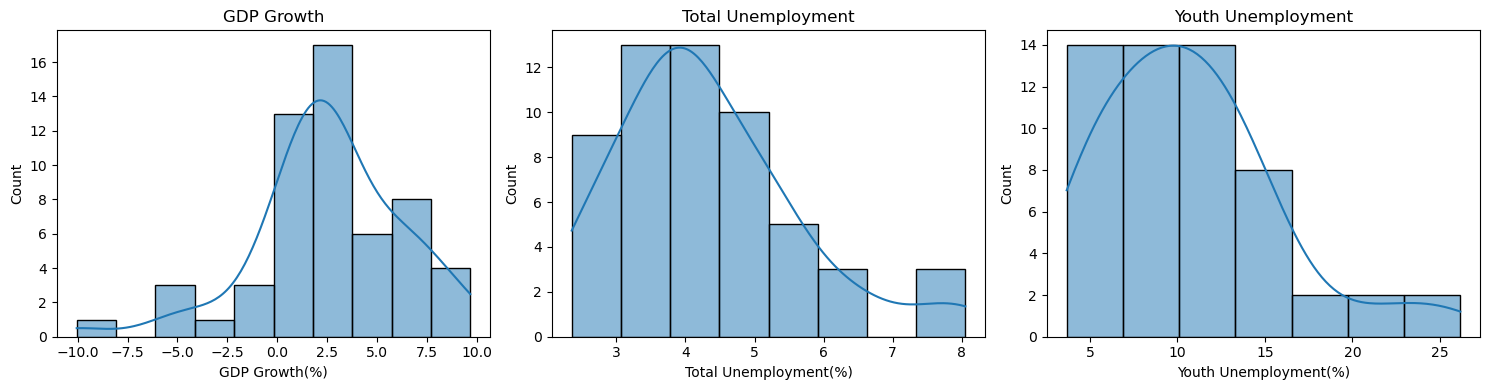

In [62]:
plt.figure(figsize=(15,4))

# GDP Growth
plt.subplot(1,3,1)
sns.histplot(df["GDP_Growth"], kde=True)
plt.title("GDP Growth")
plt.xlabel("GDP Growth(%)")

# Total Unemployment
plt.subplot(1,3,2)
sns.histplot(df["Unemployment_Total"], kde=True)
plt.title("Total Unemployment")
plt.xlabel("Total Unemployment(%)")

# Youth Unemployment
plt.subplot(1,3,3)
sns.histplot(df["Youth_Unemployment"], kde=True)
plt.title("Youth Unemployment")
plt.xlabel("Youth Unemployment(%)")

plt.tight_layout()
plt.show()

#### Observation
* Most GDP growth values are positive, while a few negative values are also present.
* Total unemployment values are mostly concentrated in a smaller range.
* Youth unemployment values are spread over a wider range and are generally higher than total unemployment values.
#### Insight
* Youth unemployment shows more variation and instability compared to overall unemployment levels.

#### 1.2 Outlier Detection using Boxplot

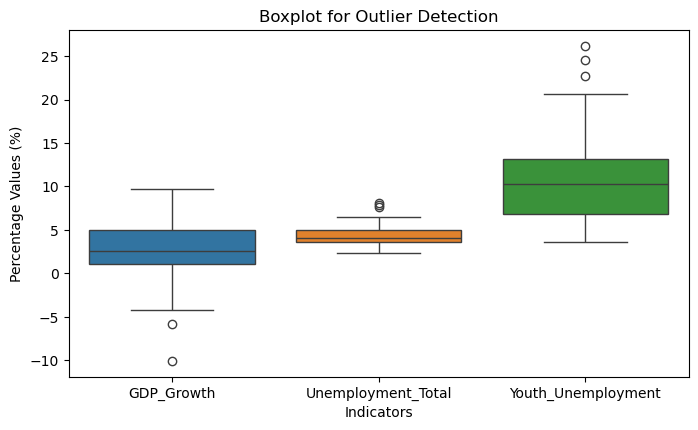

In [63]:
plt.figure(figsize=(8,4.5))

sns.boxplot(data=df[[
    "GDP_Growth",
    "Unemployment_Total",
    "Youth_Unemployment"
]])

plt.title("Boxplot for Outlier Detection")
plt.xlabel("Indicators")
plt.ylabel("Percentage Values (%)")

plt.show()

#### Observation
* GDP growth contains a few negative outliers representing economic downturn periods.
* Total unemployment shows relatively smaller variation compared to youth unemployment.
* Youth unemployment contains multiple higher outliers, indicating severe employment instability in certain cases.
#### Insight
* Economic disruptions affected youth employment more strongly, while GDP growth showed significant fluctuations during abnormal economic periods.

## 2. Bivariate Analysis

#### 2.1 Relationship Between GDP Growth and Unemployment

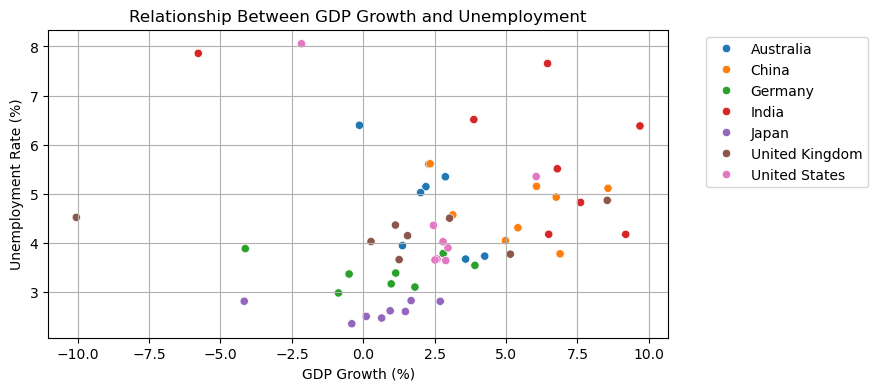

In [64]:
plt.figure(figsize=(8,4))

sns.scatterplot(data=df,
                x="GDP_Growth",
                y="Unemployment_Total",
                hue="Country")

plt.title("Relationship Between GDP Growth and Unemployment")
plt.xlabel("GDP Growth (%)")
plt.ylabel("Unemployment Rate (%)")

plt.legend(bbox_to_anchor=(1.05, 1))

plt.grid(True)

plt.show()

#### Observation

* Most points are concentrated in the positive GDP growth region between 0% and 7%.
* India shows comparatively higher unemployment value in several observations.
* One observation shows extremely low GDP growth near -10% while unemployment remains around 4–5%.
* Japan and Germany mostly appear in the lower unemployment region compared to some other countries.

#### Insight

* Lower GDP growth generally tends to be associated with higher unemployment.
* However, unemployment does not always increase immediately even when GDP falls sharply, as seen during major economic disruptions like COVID-19.


#### 2.2 Relationship Between Total and Youth Unemployment

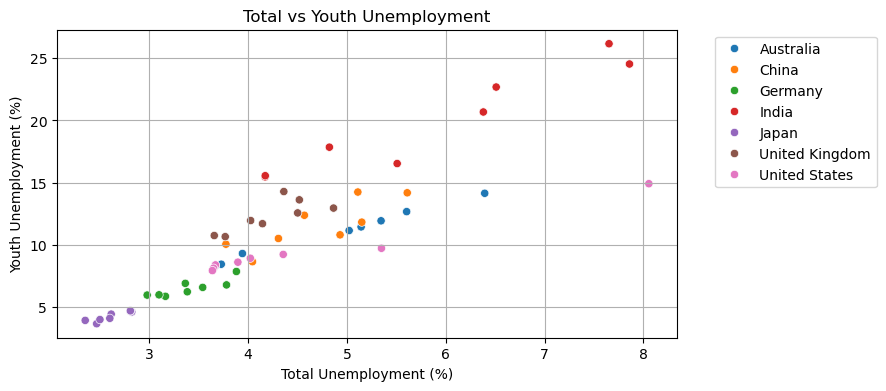

In [65]:
plt.figure(figsize=(8,4))

sns.scatterplot(data=df,
                x="Unemployment_Total",
                y="Youth_Unemployment",
                hue="Country")

plt.title("Total vs Youth Unemployment")
plt.xlabel("Total Unemployment (%)")
plt.ylabel("Youth Unemployment (%)")

plt.legend(bbox_to_anchor=(1.05, 1))
plt.grid(True)
plt.show()

#### Observation

* Youth unemployment increases as total unemployment increases.
* Japan and Germany mostly show lower total and youth unemployment values.
* India shows the highest youth unemployment values, reaching above 20% in some observations.

#### Insight

* Countries with higher overall unemployment tend to experience even higher youth unemployment, showing that younger populations are more affected by employment instability.


## 3. Time Series Trend Analysis

#### 3.1 Total Unemployment Trends across Countries

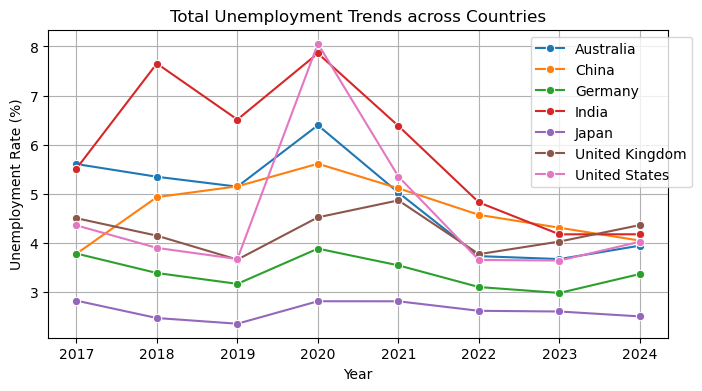

In [66]:
plt.figure(figsize=(8,4))

sns.lineplot(data=df,
             x="Year",
             y="Unemployment_Total",
             hue="Country",
             marker='o')

plt.title("Total Unemployment Trends across Countries")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")

plt.legend(bbox_to_anchor=(1.05, 1))

plt.grid(True)

plt.show()


#### Observation
- India shows the highest unemployment rates in most years, with a peak near 8% in 2020.
- Japan consistently maintains the lowest unemployment rate among all countries.
- Most countries show an increase in unemployment during 2020–2021.
- Japan, Germany and the United Kingdom maintain relatively stable unemployment trends.
#### Insight
- Employment was affected in many countries during 2020.
- Countries like Japan and Germany show stronger employment stability compared to others.

#### 3.2. GDP Growth across Countries

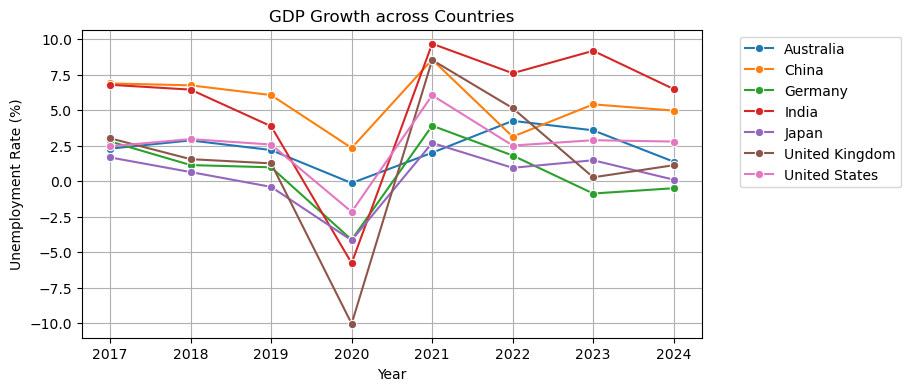

In [67]:
plt.figure(figsize=(8,4))

sns.lineplot(data=df,
             x="Year",
             y="GDP_Growth",
             hue="Country",
             marker='o')

plt.title("GDP Growth across Countries")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")

plt.legend(bbox_to_anchor=(1.05, 1))

plt.grid(True)

plt.show()

#### Observation
- Almost all countries experienced a sharp GDP decline in 2020.
- The United Kingdom shows the largest GDP drop, close to -10%.
- India shows strong GDP recovery in 2021 after the sharp decline in 2020.
#### Insight
- The global economic slowdown during 2020 affected all countries significantly.
- Several countries showed economic recovery after 2020, but recovery strength differed across countries.

## 4. Correlation Analysis

                    GDP_Growth  Unemployment_Total  Youth_Unemployment
GDP_Growth             1.00000            0.135950            0.252860
Unemployment_Total     0.13595            1.000000            0.877042
Youth_Unemployment     0.25286            0.877042            1.000000


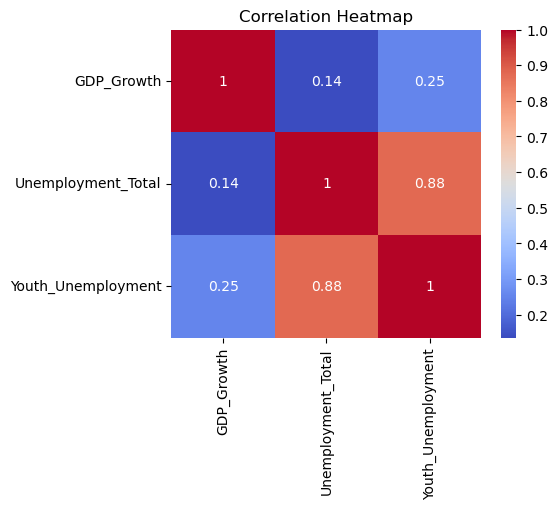

In [68]:
#Correlation Analysis
correlation = df[[
    "GDP_Growth",
    "Unemployment_Total",
    "Youth_Unemployment"
]].corr()

print(correlation)

#Correlation Heatmap
plt.figure(figsize=(5,4))

sns.heatmap(correlation,
            annot=True,
            cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

#### Observation

* Total unemployment and youth unemployment have a very strong positive correlation (0.88).
* GDP growth has weak correlation with both unemployment indicators.

#### Insight

* Countries with higher total unemployment generally also experience higher youth unemployment.
* GDP growth alone may not strongly explain unemployment variation in this dataset.


# Conclusion

This project analyzed GDP growth, total unemployment, and youth unemployment across seven countries from 2017 to 2024 using World Bank data.

The analysis revealed a strong positive correlation between total unemployment and youth unemployment (approximately 0.88), while GDP growth showed relatively weak correlations with both unemployment indicators. The visualizations also highlighted differences in unemployment levels across countries and the economic downturn experienced in 2020.

Overall, this project demonstrates how data analytics can help identify economic patterns, compare country-level trends, and generate meaningful insights from historical data.

# Limitations

- The analysis covers seven selected countries from 2017 to 2024, providing a limited view of global unemployment and economic trends.
- The observed relationships between economic indicators do not necessarily imply cause and effect.

## Future Scope
- The analysis can be extended to more countries and years to understand global unemployment and economic trends more broadly.
- Additional economic and social indicators can be included to explore unemployment trends in greater detail.